# Diagnóstico del modelo de ML — Duración del viaje (`trip_duration`)

Notebook de diagnóstico para el caso de uso duration (etiqueta `trip_duration_minutes`).

Sin reentrenamiento: carga el modelo `@champion` del Model Registry de MLflow y lo analiza sobre las tablas gold. Es uno de los tres notebooks de diagnóstico por caso de uso (`fare` / `duration` / `demand`); el cuerpo del análisis es idéntico en los tres.

Secciones:
1. Parámetros y configuración (Spark y MLflow).
2. Carga del modelo `@champion` y metadatos registrados.
3. Reconstrucción de los splits y métricas por split.
4. Predicción vs Real en `common_test`.
5. Residuos.
6. Importancia de las features.
7. Fase 2 — Más datos A vs B.
8. Baseline vs champion.
9. Conclusiones.

## 1. Parámetros

`USE_CASE` está fijado a `duration` en este notebook.

In [1]:
USE_CASE = "duration"

from ml.train import USE_CASES
from ml.splits import TEST_YEAR, TRAIN_VAL_YEARS

cfg = USE_CASES[USE_CASE]
EXPERIMENT = cfg["experiment"]
SOURCE     = cfg["source"]
LABEL      = cfg["label_col"]
YEAR_COL   = cfg["year_col"]
print(f"USE_CASE={USE_CASE}  EXPERIMENT={EXPERIMENT}  LABEL={LABEL}")
print(f"Partición: TRAIN_VAL_YEARS={TRAIN_VAL_YEARS}  TEST_YEAR={TEST_YEAR}")

USE_CASE=duration  EXPERIMENT=trip_duration  LABEL=trip_duration_minutes
Partición: TRAIN_VAL_YEARS=[2023, 2024]  TEST_YEAR=2025


In [2]:
import mlflow
from mlflow import MlflowClient
from pyspark.ml.feature import VectorAssembler
from pyspark.sql.functions import col
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from ml.splits import add_cyclical_features, make_splits
from ml.tracking import (
    compute_baseline_metrics,
    evaluate_predictions,
    get_ml_spark,
    setup_mlflow,
)

spark = get_ml_spark(f"ml-{USE_CASE}-diagnostics")
setup_mlflow(EXPERIMENT)
client = MlflowClient()
spark.version

26/07/23 20:15:54 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


'3.5.8'

## 2. Carga del modelo `@champion` desde el Registry

El alias `@champion` devuelve siempre la última versión promovida. Para una versión anterior, usa `client.get_model_version(EXPERIMENT, "3")`.

In [3]:
mv = client.get_model_version_by_alias(name=EXPERIMENT, alias="champion")
source_run = client.get_run(mv.run_id)
print(f"Modelo registrado:   {EXPERIMENT} v{mv.version}")
print(f"Run de origen:       {mv.run_id}")
print(f"Nombre del run:      {source_run.data.tags.get('mlflow.runName')}")
print(f"Algoritmo:           {source_run.data.tags.get('algorithm')}")
print(f"Fase:                {source_run.data.tags.get('phase')}")
print(f"Datos entrenamiento: {source_run.data.tags.get('training_data')}")
print(f"Creado por:          {source_run.data.tags.get('created_by')}")
print(f"Iniciado:            {pd.Timestamp(source_run.info.start_time, unit='ms')}")

print("\nCaracterísticas de servicio:")
lat = mv.tags.get("inference_latency_ms_per_row")
if lat is not None:
    print(f"  Latencia de inferencia: {float(lat):.3f} ms/fila "
          f"(muestra de {mv.tags.get('inference_latency_sample_n')} filas)")
print(f"  Estado de validación:   {mv.tags.get('validation_status')}")
print(f"  Fecha de despliegue:    {mv.tags.get('deployment_date')}")

print("\nAnclajes de reproducibilidad:")
print(f"  Nessie main hash:   {mv.tags.get('nessie_main_hash')}")
print(f"  Snapshot de origen: {mv.tags.get('source_snapshot_id')}")

print(f"\nDescripción:\n  {mv.description or '(ninguna)'}\n")
print("Tags de la versión:")
for k, v in sorted(mv.tags.items()):
    print(f"  {k}: {v}")

Modelo registrado:   trip_duration v2
Run de origen:       070c6c1da1c240ffa9dc272af7b8c1c5
Nombre del run:      train-gbt
Algoritmo:           gbt
Fase:                training
Datos entrenamiento: [2023, 2024]
Creado por:          jgalanllano
Iniciado:            2026-07-18 05:58:54.191000

Características de servicio:
  Latencia de inferencia: 1.055 ms/fila (muestra de 1000 filas)
  Estado de validación:   champion
  Fecha de despliegue:    2026-07-18T13:27:47+00:00

Anclajes de reproducibilidad:
  Nessie main hash:   c577394a0346547d8e3f36465d984559ef38fd48de7b8cf0b7920c4ae2f4c159
  Snapshot de origen: 7335230494356809279

Descripción:
  Run name: train-gbt. Algorithm: gbt. Phase: training.
Params: {'maxIter': 50, 'maxDepth': 6, 'stepSize': 0.1, 'subsamplingRate': 1.0, 'featureSubsetStrategy': 'all', 'maxBins': 300, 'seed': 42}.
Source: nessie.nyc.yellow_taxi_trips (Nessie main hash=c577394a0346, snapshot_id=7335230494356809279). Target: trip_duration_minutes.
Training data: [2023,

In [4]:
metrics_df = pd.DataFrame.from_dict(source_run.data.metrics, orient='index', columns=['valor'])
params_df  = pd.DataFrame.from_dict(source_run.data.params,  orient='index', columns=['valor'])
display(metrics_df.sort_index())
display(params_df.sort_index())

,valor
common_test_mae,2.743036
common_test_r2,0.844876
common_test_rmse,4.458196
cv_avg_rmse_grid_0,4.478898
cv_avg_rmse_grid_1,4.354022
cv_avg_rmse_grid_2,4.247038
cv_avg_rmse_grid_3,4.430202
cv_best_avg_rmse,4.247038
train_mae,2.710332
train_r2,0.853201


,valor
best_featureSubsetStrategy,all
best_grid_idx,2
best_maxBins,300
best_maxDepth,6
best_maxIter,50
best_seed,42
best_stepSize,0.1
best_subsamplingRate,1.0
categorical_cols,"pu_location_id,do_location_id,vendor_id,rateco..."
common_test_count,8080072


In [5]:
model_uri = f"models:/{EXPERIMENT}@champion"

import os, shutil
from mlflow.artifacts import download_artifacts
from pyspark.ml import PipelineModel

local_model = download_artifacts(artifact_uri=model_uri)
shared_dir = "/opt/spark/src/.tmp_ingest/champion_sparkml"
shutil.rmtree(shared_dir, ignore_errors=True)
shutil.copytree(os.path.join(local_model, "sparkml"), shared_dir)
model = PipelineModel.load(f"file://{shared_dir}")
print(f"Etapas del pipeline ({len(model.stages)}):")
for i, stage in enumerate(model.stages):
    print(f"  {i}: {type(stage).__name__}")

Etapas del pipeline (8):
  0: StringIndexerModel
  1: StringIndexerModel
  2: StringIndexerModel
  3: StringIndexerModel
  4: StringIndexerModel
  5: VectorAssembler
  6: VectorIndexerModel
  7: GBTRegressionModel


## 3. Reconstrucción de los splits y métricas por split

`make_splits` usa `seed=42` y se reaplica el mismo muestreo (`sample_fraction` del run de origen), así que `train` / `val` / `common_test` se reconstruyen de forma reproducible: los recuentos deben coincidir con los tags `*_count` de la versión registrada.

Las métricas por split ya están registradas en el run, así que se leen en vez de recalcularse. La reconstrucción sigue siendo necesaria para producir las predicciones del champion sobre `common_test`, que MLflow no almacena y que usan las secciones 4, 5 y 8.

In [6]:
cols_to_keep = [LABEL, YEAR_COL, *cfg["numerical_cols"], *cfg["categorical_cols"]]
df = spark.table(SOURCE).select(*cols_to_keep)
if cfg["label_filter_predicate"] is not None:
    df = df.filter(cfg["label_filter_predicate"](col(LABEL)))

run_sample_fraction = source_run.data.params.get("sample_fraction")
if run_sample_fraction is not None:
    sf = float(run_sample_fraction)
    if 0.0 < sf < 1.0:
        df = df.sample(sf, seed=42)
        print(f"Muestreo del entrenamiento reaplicado: fracción={sf:.2f}, seed=42")
    else:
        print(f"sample_fraction={sf} -> sin muestreo.")
else:
    print("El run de origen no tiene el parámetro sample_fraction (anterior a la introducción del muestreo) -> se usan todos los datos.")

df, _ = add_cyclical_features(df, cfg["numerical_cols"])
train, val, common_test = make_splits(df, YEAR_COL)

recon = {"train": train.count(), "val": val.count(), "common_test": common_test.count()}
val.unpersist()
tags = {s: source_run.data.params.get(f"{s}_count") for s in ("train", "val", "common_test")}
print("\nTamaños de los subconjuntos (reconstruido vs tag del run):")
print(f"  {'subconjunto':<12} {'reconstruido':>14} {'tag':>14}")
for s in ("train", "val", "common_test"):
    print(f"  {s:<12} {recon[s]:>14,} {str(tags[s]):>14}")
print(f"\ntrain+val = TRAIN_VAL_YEARS {TRAIN_VAL_YEARS}   common_test = TEST_YEAR {TEST_YEAR} (reservado)")

M = source_run.data.metrics
por_subconjunto = pd.DataFrame(
    [{"subconjunto": s, "rmse": M.get(f"{s}_rmse"), "mae": M.get(f"{s}_mae"), "r2": M.get(f"{s}_r2")}
     for s in ("train", "val", "common_test")]
)
print("\nMétricas del champion por subconjunto (del run registrado):")
display(por_subconjunto)

pred_ct = model.transform(common_test).select(LABEL, "prediction").cache()
print(f"\ncommon_test puntuado y cacheado: {pred_ct.count():,} filas")

sample_fraction=1.0 -> sin muestreo.



Tamaños de los subconjuntos (reconstruido vs tag del run):
  subconjunto    reconstruido            tag
  train            13,866,434       13866307
  val               2,446,819        2446946
  common_test       8,080,072        8080072

train+val = TRAIN_VAL_YEARS [2023, 2024]   common_test = TEST_YEAR 2025 (reservado)

Métricas del champion por subconjunto (del run registrado):


,subconjunto,rmse,mae,r2
0,train,4.183756,2.710332,0.853201
1,val,4.217959,2.717785,0.849981
2,common_test,4.458196,2.743036,0.844876



common_test puntuado y cacheado: 8,080,072 filas


## 4. Predicción vs Real en `common_test`

Muestra del 5 % de `common_test` traída a pandas. Los puntos deberían alinearse cerca de `y = x`; una curvatura o un sesgo sistemático indica mala calibración.

In [7]:
sample_fraction = 0.05
pdf = pred_ct.sample(sample_fraction, seed=42).toPandas()
pdf['residuo'] = pdf[LABEL] - pdf['prediction']
print(f"Muestra de common_test: {len(pdf):,} filas ({sample_fraction:.0%})")
pdf.describe()

Muestra de common_test: 404,511 filas (5%)


,trip_duration_minutes,prediction,residuo
count,404511.000000,404511.000000,404511.000000
mean,13.769726,13.642238,0.127488
std,11.271114,10.393901,4.443227
min,0.016667,-10.024584,-123.974670
25%,6.883333,7.199508,-1.904259
50%,10.950000,11.080130,-0.232472
75%,16.916667,16.640578,1.661629
max,167.766667,130.575193,109.487043


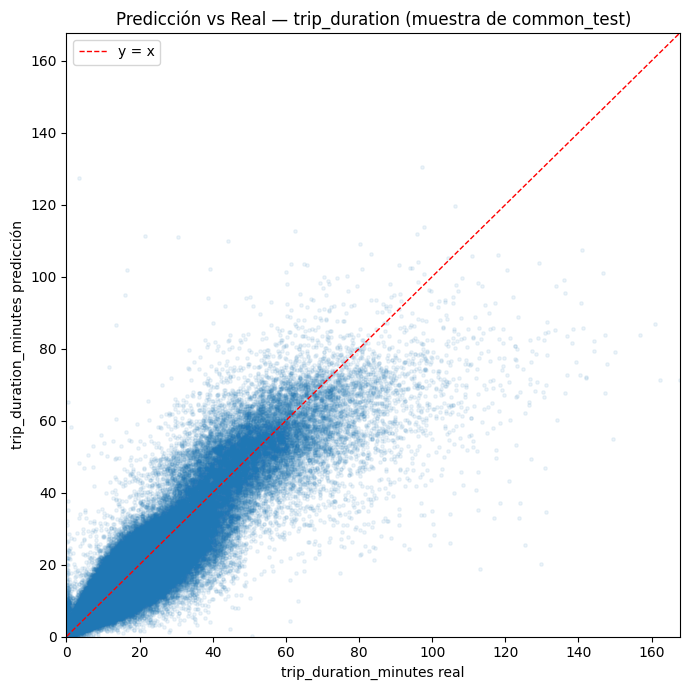

In [8]:
fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(pdf[LABEL], pdf['prediction'], alpha=0.08, s=6)
lim = float(max(pdf[LABEL].max(), pdf['prediction'].max()))
ax.plot([0, lim], [0, lim], 'r--', linewidth=1, label='y = x')
ax.set_xlabel(f'{LABEL} real')
ax.set_ylabel(f'{LABEL} predicción')
ax.set_title(f'Predicción vs Real — {EXPERIMENT} (muestra de common_test)')
ax.set_xlim(0, lim)
ax.set_ylim(0, lim)
ax.legend()
plt.tight_layout()

## 5. Residuos

- Residuo vs predicción: bandas horizontales indican error homocedástico; un embudo, heterocedasticidad.
- Histograma de residuos: debería estar centrado en 0 y ser simétrico. La asimetría indica sobre o infra-predicción sistemática.

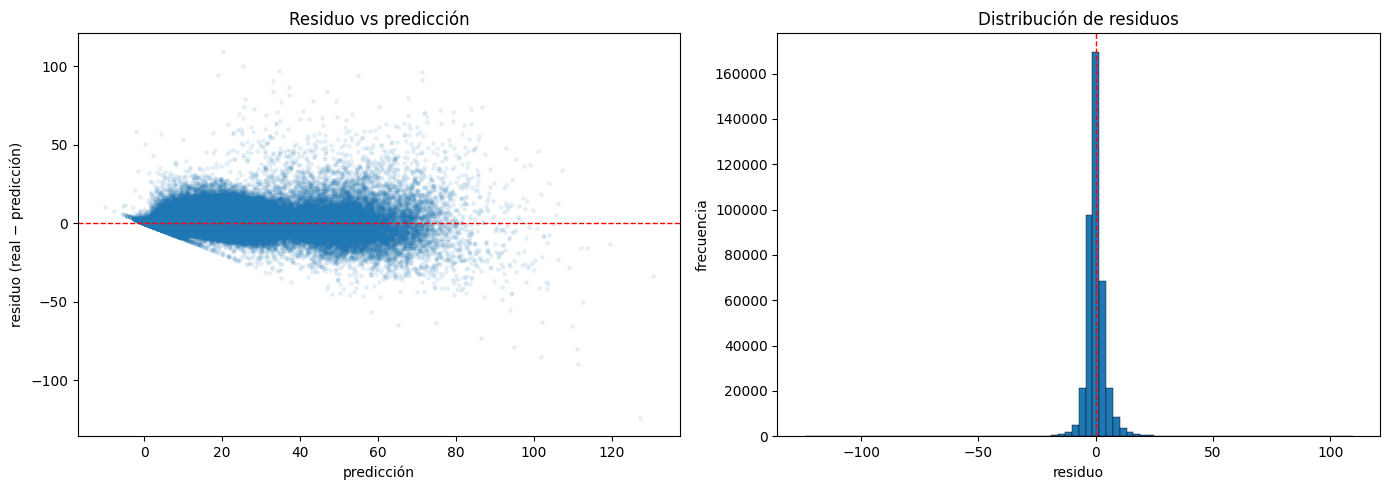

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(pdf['prediction'], pdf['residuo'], alpha=0.08, s=6)
axes[0].axhline(0, color='r', linestyle='--', linewidth=1)
axes[0].set_xlabel('predicción')
axes[0].set_ylabel('residuo (real − predicción)')
axes[0].set_title('Residuo vs predicción')
axes[1].hist(pdf['residuo'], bins=80, edgecolor='black', linewidth=0.3)
axes[1].axvline(0, color='r', linestyle='--', linewidth=1)
axes[1].set_xlabel('residuo')
axes[1].set_ylabel('frecuencia')
axes[1].set_title('Distribución de residuos')
plt.tight_layout()

## 6. Importancia de las features

- GBT / RFR: `featureImportances` (reducción media de impureza).
- GLR: `abs(coefficients)`. Las features de GLR están estandarizadas, así que las magnitudes son comparables entre columnas.

,feature,importancia
0,ratecode_id_idx,0.303527
1,trip_distance,0.249861
2,do_location_id_idx,0.143751
3,pu_location_id_idx,0.114927
4,pickup_hour,0.109863
5,pickup_dow,0.056707
6,pickup_week,0.014791
7,payment_type_idx,0.004151
8,pickup_month,0.001545
9,vendor_id_idx,0.000500


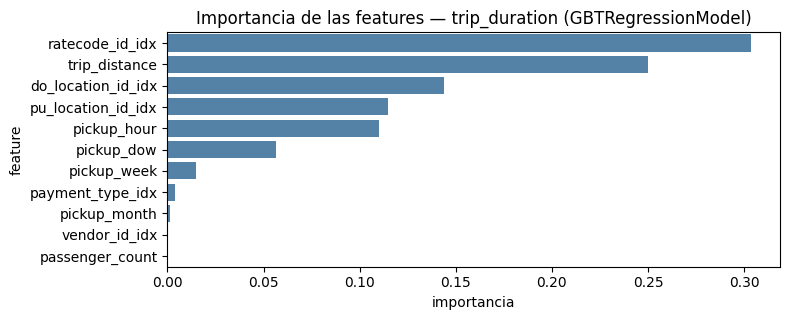

In [10]:
final = model.stages[-1]
algorithm = type(final).__name__
asm = next((s for s in model.stages if isinstance(s, VectorAssembler) and s.getOutputCol() == 'assembled_features'), None)
inputs = list(asm.getInputCols()) if asm is not None else None

if hasattr(final, 'featureImportances'):
    values = final.featureImportances.toArray(); metric_name = 'importancia'
elif hasattr(final, 'coefficients'):
    values = abs(final.coefficients.toArray()); metric_name = 'coef_abs'
else:
    raise RuntimeError(f'El modelo {algorithm} no expone featureImportances ni coefficients')

label_col = 'feature' if inputs is not None and len(inputs) == len(values) else 'feature_idx'
labels = inputs if label_col == 'feature' else list(range(len(values)))
fi = (
    pd.DataFrame({label_col: labels, metric_name: values})
    .sort_values(metric_name, ascending=False)
    .reset_index(drop=True)
)
top = fi.head(30)
display(top)

fig, ax = plt.subplots(figsize=(8, max(3, 0.3 * len(top))))
sns.barplot(data=top, x=metric_name, y=label_col, ax=ax, color='steelblue')
ax.set_title(f'Importancia de las features — {EXPERIMENT} ({algorithm})')
plt.tight_layout()

## 7. Fase 2 — Más datos: A vs B

Compara el `common_test_rmse` del run `more-data-A` (el ganador reentrenado sobre `SUBSET_A_YEARS`) con el del ganador de la Fase 1 (= B, entrenado sobre todo `TRAIN_VAL_YEARS`), identificados por su tag `more_data_subset`. Ambos se puntúan sobre el mismo año reservado (`TEST_YEAR`), así que el contraste aísla si más datos de entrenamiento ayudan a generalizar a un año futuro.

Nota: train.py etiqueta al ganador de la Fase 1 como `more_data_subset='B'` en vez de reentrenarlo, porque el reentrenamiento sería idéntico.

In [11]:
exp = client.get_experiment_by_name(EXPERIMENT)
def _latest_more_data(subset):
    return client.search_runs(
        [exp.experiment_id],
        filter_string=f"tags.more_data_subset = '{subset}' and attributes.status = 'FINISHED'",
        order_by=['attributes.start_time DESC'], max_results=10,
    )
md_runs = _latest_more_data('A') + _latest_more_data('B')
md = pd.DataFrame([
    {
        'run_name':         r.data.tags.get('mlflow.runName'),
        'subset':           r.data.tags.get('more_data_subset'),
        'training_data':    r.data.tags.get('training_data'),
        'algorithm':        r.data.tags.get('algorithm'),
        'val_rmse':         r.data.metrics.get('val_rmse'),
        'common_test_rmse': r.data.metrics.get('common_test_rmse'),
        'common_test_mae':  r.data.metrics.get('common_test_mae'),
        'common_test_r2':   r.data.metrics.get('common_test_r2'),
        'start_time':       pd.Timestamp(r.info.start_time, unit='ms'),
    } for r in md_runs
])
latest_pair = md.sort_values('start_time', ascending=False).drop_duplicates(subset='subset').head(2)
display(latest_pair[['subset', 'training_data', 'val_rmse',
                     'common_test_rmse', 'common_test_mae', 'common_test_r2']])

if len(latest_pair) == 2:
    a = latest_pair[latest_pair['subset'] == 'A'].iloc[0]
    b = latest_pair[latest_pair['subset'] == 'B'].iloc[0]
    delta = b['common_test_rmse'] - a['common_test_rmse']
    pct = 100 * delta / a['common_test_rmse']
    veredicto = ('B mejor' if delta < 0 else 'A mejor' if delta > 0 else 'empate')
    print(f"\nCambio A → B en common_test_rmse: {delta:+.4f} ({pct:+.2f}%) — {veredicto}")

,subset,training_data,val_rmse,common_test_rmse,common_test_mae,common_test_r2
0,A,[2023],4.319553,4.676853,2.754416,0.829287
1,B,"[2023, 2024]",4.217959,4.458196,2.743036,0.844876



Cambio A → B en common_test_rmse: -0.2187 (-4.68%) — B mejor


## 8. Baseline vs champion

El baseline predice `mean(label)` por `group_cols`, calculado sobre el conjunto de entrenamiento y con la media global como respaldo para los grupos no vistos en `common_test`. Media y no mediana porque se reporta RMSE: la media por grupo es el predictor constante por grupo óptimo en RMSE. El champion debería superar este suelo por un margen apreciable.

In [12]:
baseline = compute_baseline_metrics(
    train_df=train, test_df=common_test,
    label_col=LABEL, group_cols=cfg['baseline_group_cols'],
)
champ = evaluate_predictions(pred_ct, LABEL)
cmp = pd.DataFrame([
    {'modelo': 'baseline (media por grupo)', **baseline},
    {'modelo': f'champion v{mv.version}',    **champ},
])
display(cmp[['modelo', 'rmse', 'mae', 'r2']])

delta = champ['rmse'] - baseline['rmse']
pct = 100 * delta / baseline['rmse']
print(f"\nchampion − baseline en common_test_rmse: {delta:+.4f} ({pct:+.2f}%)")

,modelo,rmse,mae,r2
0,baseline (media por grupo),9.314158,6.389526,0.322909
1,champion v2,4.458196,2.743036,0.844876



champion − baseline en common_test_rmse: -4.8560 (-52.14%)


## 9. Conclusiones — Duración del viaje

Modelo `@champion`: `trip_duration` v2, un GBT (`maxDepth=6`, `maxIter=50`) entrenado sobre 2023–2024. Lectura del diagnóstico:

- Sobreajuste por selección (§3). Sin evidencia: `train` (RMSE 4,18, R² 0,853) ≤ `val` (4,22, 0,850) < `common_test` (4,46, 0,845), con saltos pequeños; la brecha `val`→`common_test` (+5,7 %) es el coste de generalizar a 2025. Los recuentos reconstruidos coinciden exactamente con los tags del entrenamiento y el RMSE de `common_test` re-puntuado (4,4582) reproduce el tag: reproducibilidad verificada.
- Calibración (§4). Residuo medio ≈ +0,14 min (sesgo despreciable, ligera infra-predicción); real medio 13,78 vs predicción 13,64. Como en tarifa, aparecen predicciones negativas en el extremo inferior (mín. −9,1) y compresión de la cola alta (predicción máx. 127 vs real 176).
- Residuos (§5). Centrados en 0, IQR casi simétrico ([−1,90; +1,66] min) y colas pesadas por viajes muy largos o atípicos; dispersión creciente con la magnitud (heterocedasticidad leve).
- Features (§6). Reparto más equilibrado que en tarifa: `ratecode_id` (0,30), `trip_distance` (0,25), zonas DO/PU (0,14/0,11) y `pickup_hour` (0,11). Coincide con el dominio: la duración depende de la distancia, de la ruta (zonas origen/destino) y del tráfico (hora del día y día de la semana).
- Más datos, B vs A (§7). B (2023–2024) mejora sobre A (2023) un −4,68 % de RMSE en 2025 (4,68→4,46): el segundo año aporta, sin saturación.
- Baseline (§8). Supera a la media-por-grupo por −52 % de RMSE (9,31→4,46), R² 0,32→0,84.
- Coste de inferencia (§2). ~1,06 ms/fila (muestra de 1000 filas de `common_test`), en el mismo orden de magnitud que el modelo de tarifa: coste de servicio bajo.